In [1]:

# STEP 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 2: Load the dataset directly from GitHub

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"

df = pd.read_csv(url)

# STEP 3: Display the first five rows

df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe().round(2))


Dataset shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values:
Pregnancies                

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [3]:

# Check zero values in relevant medical measurements

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("Zero values before cleaning:")

for col in zero_columns:
    print(f"{col}: {(df[col] == 0).sum()}")

# Make a copy so the original data remains unchanged
clean_df = df.copy()

# Treat zero values in these measurements as missing
clean_df[zero_columns] = clean_df[zero_columns].replace(0, np.nan)

# Fill missing measurements with their column medians
for col in zero_columns:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nCleaned dataset shape:", clean_df.shape)


Zero values before cleaning:
Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11

Missing values after cleaning:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Cleaned dataset shape: (768, 9)


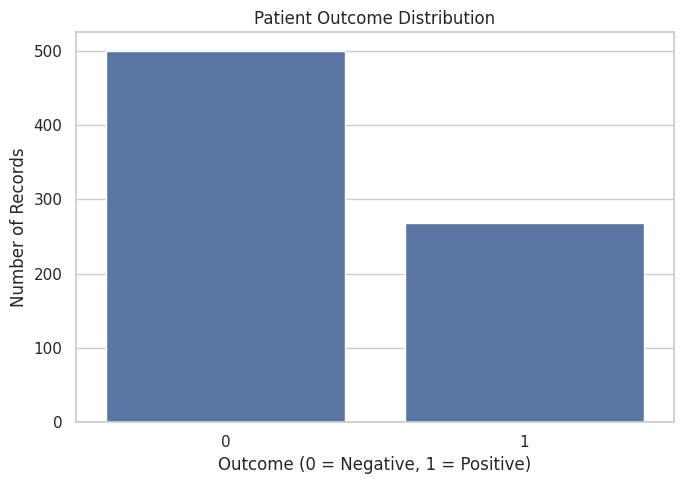

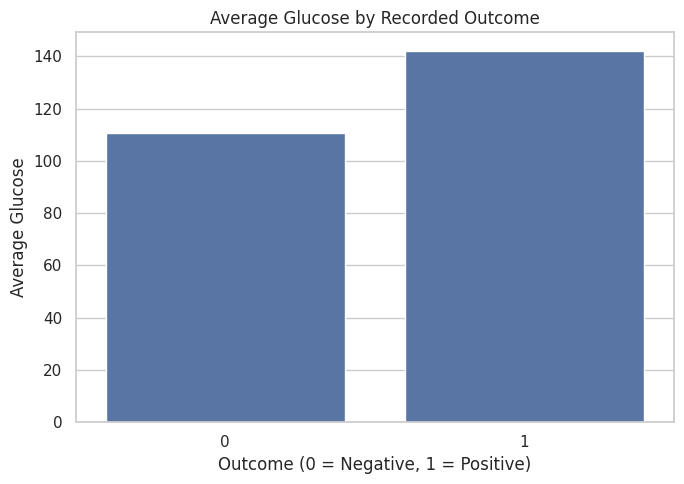

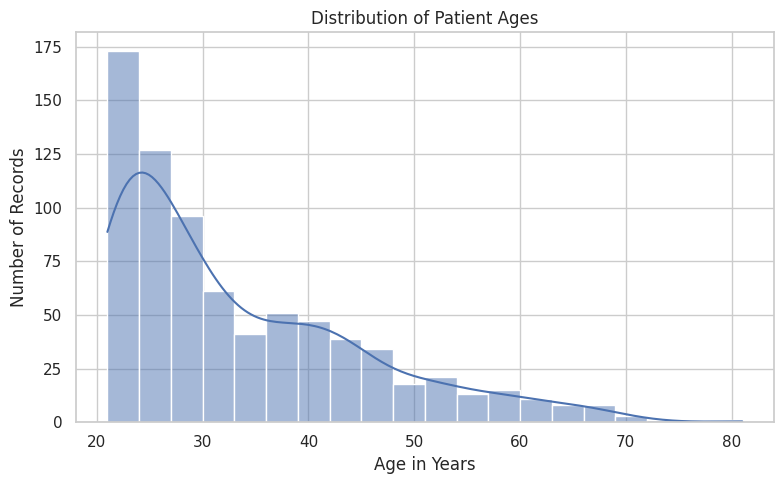

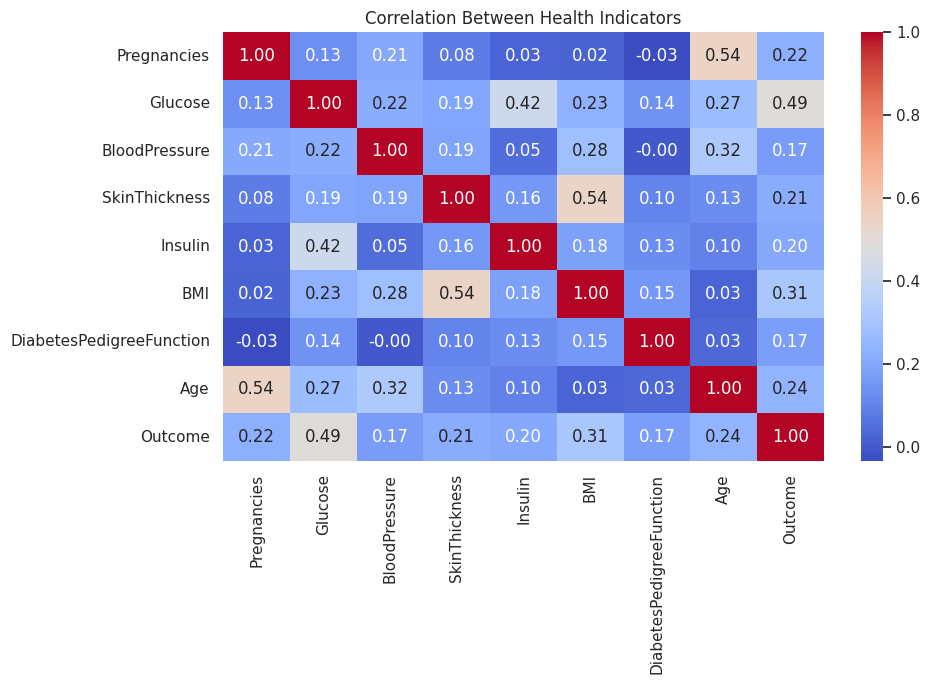

In [4]:

# Set a consistent visual style
sns.set_theme(style="whitegrid")

# Chart 1: Diabetes outcome distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=clean_df,
    x="Outcome"
)

plt.title("Patient Outcome Distribution")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Chart 2: Average glucose by outcome
plt.figure(figsize=(7, 5))

sns.barplot(
    data=clean_df,
    x="Outcome",
    y="Glucose",
    errorbar=None
)

plt.title("Average Glucose by Recorded Outcome")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Average Glucose")
plt.tight_layout()
plt.show()

# Chart 3: Age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=clean_df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Distribution of Patient Ages")
plt.xlabel("Age in Years")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Chart 4: Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    clean_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Health Indicators")
plt.tight_layout()
plt.show()


In [5]:

# Count patients in each outcome group

outcome_counts = clean_df["Outcome"].value_counts().sort_index()

print("Outcome Distribution")
print("0 = Negative outcome")
print("1 = Positive outcome")
print(outcome_counts)

# Calculate percentages
outcome_percentages = (
    clean_df["Outcome"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("\nOutcome percentages:")
print(outcome_percentages.round(2))

print("\nTotal records:", len(clean_df))


Outcome Distribution
0 = Negative outcome
1 = Positive outcome
Outcome
0    500
1    268
Name: count, dtype: int64

Outcome percentages:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64

Total records: 768


In [6]:

# Compare average health indicators by recorded outcome

comparison = clean_df.groupby("Outcome")[
    ["Glucose", "BloodPressure", "BMI", "Age", "Insulin"]
].mean().round(2)

print("Average Health Indicators by Outcome")
display(comparison)


Average Health Indicators by Outcome


,Glucose,BloodPressure,BMI,Age,Insulin
Outcome,,,,,
0,110.68,70.92,30.89,31.19,127.79
1,142.13,75.12,35.38,37.07,164.70


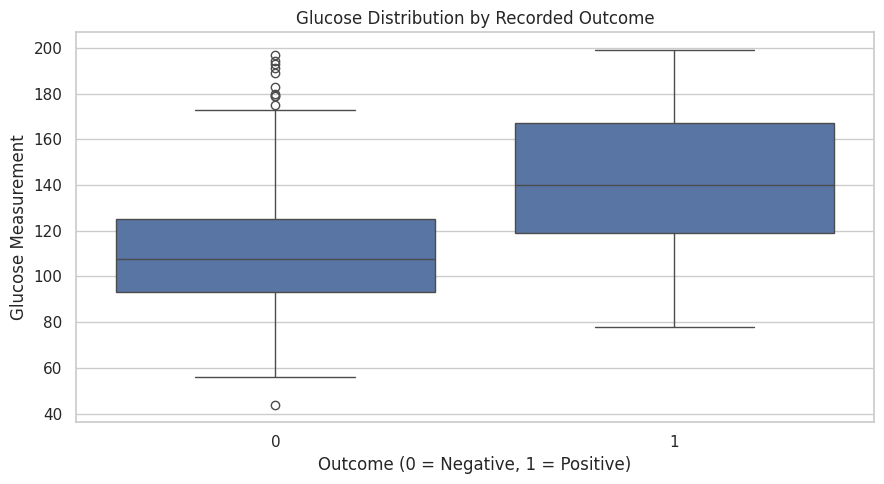

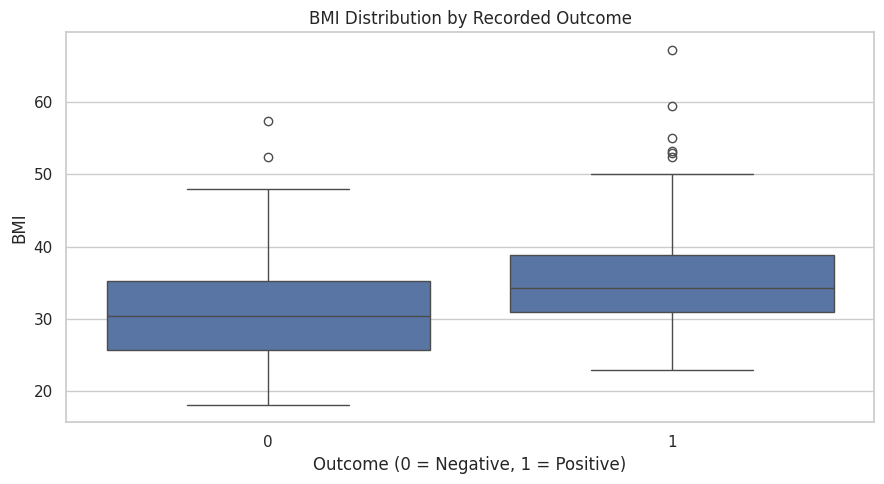

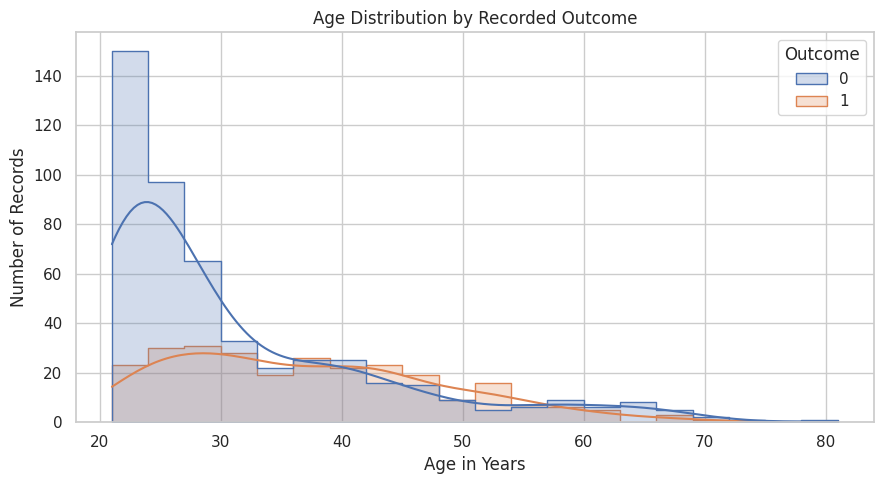

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Compare glucose distributions
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clean_df,
    x="Outcome",
    y="Glucose"
)

plt.title("Glucose Distribution by Recorded Outcome")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Glucose Measurement")
plt.tight_layout()
plt.show()

# Compare BMI distributions
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clean_df,
    x="Outcome",
    y="BMI"
)

plt.title("BMI Distribution by Recorded Outcome")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()

# Compare age distributions
plt.figure(figsize=(9, 5))

sns.histplot(
    data=clean_df,
    x="Age",
    hue="Outcome",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Age Distribution by Recorded Outcome")
plt.xlabel("Age in Years")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [8]:

total_records = len(clean_df)
positive_records = (clean_df["Outcome"] == 1).sum()
negative_records = (clean_df["Outcome"] == 0).sum()

positive_percentage = positive_records / total_records * 100

print("HEALTHCARE PATIENT METRICS")
print("-" * 35)
print("Total patient records:", total_records)
print("Positive outcome records:", positive_records)
print("Negative outcome records:", negative_records)
print("Positive outcome percentage:", round(positive_percentage, 2), "%")
print("Average age:", round(clean_df["Age"].mean(), 2))
print("Average glucose:", round(clean_df["Glucose"].mean(), 2))
print("Average BMI:", round(clean_df["BMI"].mean(), 2))


HEALTHCARE PATIENT METRICS
-----------------------------------
Total patient records: 768
Positive outcome records: 268
Negative outcome records: 500
Positive outcome percentage: 34.9 %
Average age: 33.24
Average glucose: 121.66
Average BMI: 32.46


In [9]:

clean_df.to_csv(
    "/content/healthcare_patient_metrics_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [11]:

from google.colab import files

files.download("/content/healthcare_patient_metrics_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

# Separate features (X) and target (y)

X = clean_df.drop("Outcome", axis=1)
y = clean_df["Outcome"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable: Outcome")
print("Features shape:", X.shape)
print("Target shape:", y.shape)


Input features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target variable: Outcome
Features shape: (768, 8)
Target shape: (768,)


In [13]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 614
Testing records: 154


In [14]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [15]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Generate predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("MODEL EVALUATION")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


MODEL EVALUATION
-----------------------------------
Accuracy: 0.708
Precision: 0.6
Recall: 0.5
F1-score: 0.545
ROC-AUC: 0.813

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



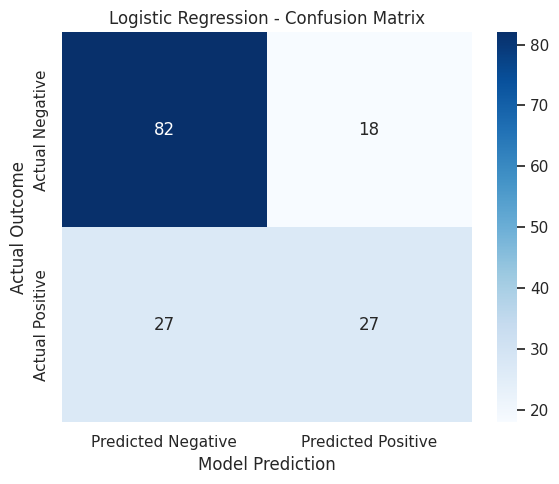

In [16]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Negative", "Predicted Positive"],
    yticklabels=["Actual Negative", "Actual Positive"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Model Prediction")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()


In [17]:

import joblib

joblib.dump(model, "/content/healthcare_logistic_model.pkl")

print("Trained model saved successfully!")


Trained model saved successfully!
